# Per-fish × per-pair gains with and without the mask QC (4-fish, Kaden masks, isolated EODs at 10 cm / 5×)

**Isolated (sure-emitter) EODs**, as before: the fish's mask midline ≥ 10 cm from every other fish's; at its top pair p* its
predicted |v| ≥ 5× every other fish's; the largest recorded |v| is at p* with the predicted sign; only one fish passes.

**Mask QC** (`kaden_mask_qc.py`, the checks of the 2- and 3-fish notebooks with the 0.8 length limit of the better list), per fish
and frame, on Kaden's visible masks: the fish has a mask; area within 20% of its median; principal-axis length 0.8–1.2 × its median;
≥ 99% in one connected piece; centroid step ≤ 15 px and area change ≤ 15% to the previous and the next frame; not within 5 px of
another fish. Medians per fish and video.

Three sets of EODs to fit on:
- **previous**: all isolated EODs (no mask QC);
- **mask QC, all four fish**: the frame is good for every fish, as the frame QC before;
- **mask QC, emitter only**: the emitting fish's mask passes (the other fish only enter the model as conductors).

**Fit**: $r_{i,p} \approx a_f\, b_p\, m_{i,f,p}$, i = EOD, f = its isolated fish, p = pair; $r$ = recorded peak pattern (V),
$m$ = my model's unit-current prediction for fish f (× −1). **Plain least squares** over all EODs and pairs, in volts, with no
per-EOD normalisation (EODs close to an electrode are loud and carry most of the information on the gains):
$\min \sum_{i,p} (r_{i,p} - a_f b_p m_{i,f,p})^2$. Solved by alternating least squares: with $b$ fixed,
$a_f = \sum r\,(b m) / \sum (b m)^2$ over fish f's EODs; with $a$ fixed, $b_p = \sum r\,(a m) / \sum (a m)^2$ over pair p of every
EOD; 200 iterations from $a = b = 1$; then $b$ scaled to a geometric mean of 1 (only $a_f b_p$ is determined, so this changes no
prediction). 95% intervals: 300 bootstrap resamples of the EODs.

**Held-out check**: fit on four videos, error on the fifth, $\lVert r - \hat r\rVert / \max|r|$ (as in the last L2 plots). To compare
the three training sets fairly, all are tested on the **same EODs: the held-out video's isolated EODs that pass the all-fish
mask QC**. Shown for shape only (prediction scaled to the EOD's recorded peak), the per-fish × per-pair gains, and one global
$g_0 L^{0.25}$, $g_0$ fitted by plain least squares on the training EODs, $g_0 = \sum r\,(L^{0.25} m) / \sum (L^{0.25} m)^2$.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
SRC = f'{BASE}/fish_pair_factors_iso10cm_dom5'
OUT = f'{BASE}/fish_pair_factors_mask_qc'; os.makedirs(OUT, exist_ok=True)
L = np.array([15.65, 13.10, 9.82, 8.51])            # cm, 90th percentile of the mask midline (EOD_L2_isolated_shape_vs_g0_L025)
E = 0.25
SETS = ['previous (no mask QC)', 'mask QC, all four fish', 'mask QC, emitter only']
COL = dict(zip(SETS, ['#8a8a85', '#1F5FBF', '#17A0B0']))
MASK, WEIGHT = {}, {s: False for s in SETS}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
peak = lambda x: np.abs(x).max(axis=-1, keepdims=True)

S = pd.read_csv(f'{SRC}/sure_emitter_eods.csv')
R, M, qc_all, qc_em = [], [], [], []
for t, g in S.groupby('video', sort=False):
    z = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    fi = g.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy()
    R.append(z['recorded_peak'][g.row]); M.append(z['mine_unit_current'][g.row.to_numpy(), fi])
    good = set(pd.read_csv(f'{BASE}/{t}/mask_qc_good_frames.csv').frame)
    q = pd.read_csv(f'{BASE}/{t}/mask_qc_per_fish.csv', usecols=['frame', 'fish', 'all']).set_index(['frame', 'fish'])['all']
    qc_all.append(g.Frame.isin(good).to_numpy())
    qc_em.append(q.reindex(list(zip(g.Frame, g.emitter))).fillna(False).to_numpy(bool))
assert (S.video.to_numpy() == np.concatenate([g.video.to_numpy() for _, g in S.groupby('video', sort=False)])).all()
R, M = np.concatenate(R), np.concatenate(M)
S['mask QC, all four fish'] = np.concatenate(qc_all); S['mask QC, emitter only'] = np.concatenate(qc_em)
S['previous (no mask QC)'] = True
FI = S.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy(); V = S.video.to_numpy(); RECS = list(dict.fromkeys(V))
S.to_csv(f'{OUT}/isolated_eods_with_mask_qc.csv', index=False)

C = pd.DataFrame({s: S[S[MASK.get(s, s)]].groupby('emitter').size().reindex(list(LET), fill_value=0) for s in SETS}).T
C['all'] = C.sum(1)
display(C)
display(pd.DataFrame({s: S[S[MASK.get(s, s)]].groupby('video').size().reindex(RECS, fill_value=0) for s in SETS}).T)

emitter,A,B,C,D,all
previous (no mask QC),6257,15559,1990,3120,26926
"mask QC, all four fish",1384,4258,297,625,6564
"mask QC, emitter only",3795,15368,1002,1249,21414


video,05_52_55,06_52_55,11_12_57,15_16_23,19_16_25
previous (no mask QC),8758,9022,996,4987,3163
"mask QC, all four fish",1421,2644,213,2045,241
"mask QC, emitter only",5506,7428,853,4640,2987


## Fit on all five videos

In [2]:
def fit(R, M, fi, fish=True, pair=True, weight=False, iters=200):
    '''Least-squares a (4,), b (10,) with R ~ a[fi, None] * b[None] * M; rows weighted by 1 / ||r|| if weight; geo-mean(b) = 1.'''
    w = 1 / np.linalg.norm(R, axis=1, keepdims=True) if weight else np.ones((len(R), 1))
    Rw, Mw = R * w, M * w
    a, b = np.ones(4), np.ones(10)
    for _ in range(iters):
        X = Mw * b
        if fish: a = np.array([(Rw[fi == f] * X[fi == f]).sum() / (X[fi == f] ** 2).sum() if (fi == f).any() else np.nan for f in range(4)])
        else: a = np.full(4, (Rw * X).sum() / (X ** 2).sum())
        if pair:
            Y = Mw * a[fi, None]; b = (Rw * Y).sum(0) / (Y ** 2).sum(0); b = b / np.exp(np.mean(np.log(np.abs(b))))
    return a, b

names = [f'fish {f}' for f in LET] + [f'pair {p}' for p in range(1, 11)]
rng = np.random.default_rng(0); rows = []
for s in SETS:
    k = S[MASK.get(s, s)].to_numpy()
    a, b = fit(R[k], M[k], FI[k], weight=WEIGHT[s])
    idx = np.flatnonzero(k)
    boot = np.array([np.r_[fit(R[i], M[i], FI[i], weight=WEIGHT[s], iters=60)] for i in (rng.choice(idx, len(idx)) for _ in range(300))])
    lo, hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)
    n = [int((FI[k] == f).sum()) for f in range(4)] + [int((S['pair p* (1-10)'][k] == p).sum()) for p in range(1, 11)]
    rows += [dict(set=s, factor=nm, gain=v, low=l, high=h, n=c) for nm, v, l, h, c in zip(names, np.r_[a, b], lo, hi, n)]
F = pd.DataFrame(rows); F.to_csv(f'{OUT}/gains_by_set.csv', index=False)
display(F.pivot_table(index='factor', columns='set', values='gain', sort=False)[SETS].round(3))

set,previous (no mask QC),"mask QC, all four fish","mask QC, emitter only"
factor,,,
fish A,0.454,0.442,0.438
fish B,0.291,0.288,0.296
fish C,0.446,0.415,0.423
fish D,0.419,0.383,0.387
pair 1,0.945,0.980,0.948
pair 2,0.754,0.756,0.742
pair 3,0.790,0.689,0.784
pair 4,0.870,0.892,0.893
pair 5,1.090,1.160,1.139


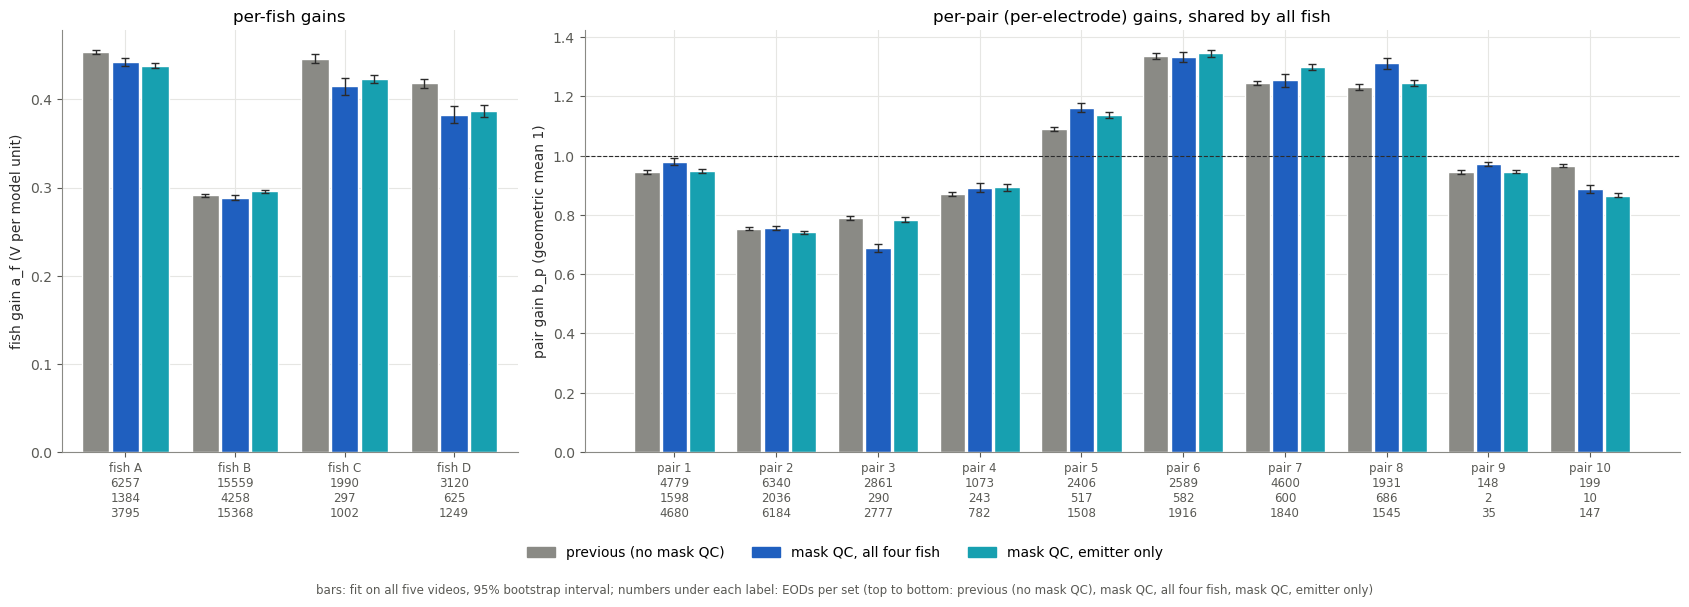

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5.4), gridspec_kw=dict(width_ratios=[1, 2.4]))
w = 0.27
for ax, sel, ylab, title in [(axs[0], names[:4], 'fish gain a_f (V per model unit)', 'per-fish gains'),
                             (axs[1], names[4:], 'pair gain b_p (geometric mean 1)', 'per-pair (per-electrode) gains, shared by all fish')]:
    x = np.arange(len(sel))
    for k, s in enumerate(SETS):
        d = F[F.set == s].set_index('factor').loc[sel]
        xs = x + (k - 1) * w
        ax.bar(xs, d.gain, w * 0.92, color=COL[s], edgecolor='white')
        ax.errorbar(xs, d.gain, yerr=[d.gain - d.low, d.high - d.gain], fmt='none', color='#2b2b2b', capsize=3, lw=1)
    ns = F.pivot_table(index='factor', columns='set', values='n', sort=False).loc[sel, SETS].astype(int)
    ax.set_xticks(x); ax.set_xticklabels([f'{nm}\n' + '\n'.join(str(v) for v in ns.loc[nm]) for nm in sel], fontsize=8.5)
    ax.set(ylabel=ylab, title=title, ylim=(0, None))
    if sel[0].startswith('pair'): ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
fig.legend(handles=[Patch(color=COL[s], label=s) for s in SETS], loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.text(0.5, -0.11, 'bars: fit on all five videos, 95% bootstrap interval; numbers under each label: EODs per set (top to bottom: '
         + ', '.join(SETS) + ')', ha='center', fontsize=8.5, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/gains_previous_vs_mask_qc.png', dpi=120, bbox_inches='tight'); plt.show()

## Held-out check: fit on four videos, test on the fifth (same test EODs for every training set)

In [4]:
test = S['mask QC, all four fish'].to_numpy()
err = []
for t in RECS:
    te = test & (V == t)
    if not te.any(): continue
    Rt, Mt, Ft = R[te], M[te], FI[te]
    e_shape = np.linalg.norm(Rt / peak(Rt) - Mt / peak(Mt), axis=1)
    for f in range(4):
        if (Ft == f).any(): err.append(dict(video=t, fish=LET[f], fit='shape only', set='—', error=np.median(e_shape[Ft == f]), n=int((Ft == f).sum())))
    err.append(dict(video=t, fish='all', fit='shape only', set='—', error=np.median(e_shape), n=len(Ft)))
    for s in SETS:
        tr = S[MASK.get(s, s)].to_numpy() & (V != t)
        a, b = fit(R[tr], M[tr], FI[tr], weight=WEIGHT[s])
        X = L[FI[tr], None] ** E * M[tr]
        g0 = (R[tr] * X).sum() / (X ** 2).sum()                          # pooled least squares
        for nm, Rh in [('per-fish × per-pair', a[Ft, None] * b[None] * Mt), ('g0 L^0.25', g0 * L[Ft, None] ** E * Mt)]:
            ev = np.linalg.norm(Rt - Rh, axis=1); e = ev / peak(Rt)[:, 0]; sq = ((Rt - Rh) ** 2).sum(1)
            for f in range(4):
                if (Ft == f).any(): err.append(dict(video=t, fish=LET[f], fit=nm, set=s, error=np.median(e[Ft == f]), error_V=np.median(ev[Ft == f]),
                                                    sq_sum=sq[Ft == f].sum(), n=int((Ft == f).sum())))
            err.append(dict(video=t, fish='all', fit=nm, set=s, error=np.median(e), error_V=np.median(ev), sq_sum=sq.sum(), n=len(Ft)))
ERR = pd.DataFrame(err); ERR.to_csv(f'{OUT}/held_out_error_by_set.csv', index=False)
# pooled over videos: EOD-weighted mean of the per-video medians
summ = ERR.groupby(['fit', 'set', 'fish'], sort=False).apply(lambda d: np.average(d.error, weights=d.n), include_groups=False).unstack('fish')[list(LET) + ['all']]
summ.to_csv(f'{OUT}/held_out_error_summary.csv')
display(summ.round(3))
summV = ERR[ERR.fit != 'shape only'].groupby(['fit', 'set', 'fish'], sort=False).apply(lambda d: np.average(d.error_V, weights=d.n), include_groups=False).unstack('fish')[list(LET) + ['all']]
summV.to_csv(f'{OUT}/held_out_error_volts_summary.csv')
print('median ‖r − r̂‖ in volts (mean over held-out videos, weighted by EODs):'); display(summV.round(4))
# the quantity the fit minimises: RMS error in volts over every held-out EOD x pair (pooled over the five held-out videos)
G = ERR[ERR.fit != 'shape only'].groupby(['fit', 'set', 'fish'], sort=False)
rms = (G.sq_sum.sum() / (10 * G.n.sum())).pow(0.5).unstack('fish')[list(LET) + ['all']]
rms.to_csv(f'{OUT}/held_out_rms_volts.csv')
print('held-out RMS error (V) over all test EOD x pair values:'); display(rms.round(4))

fish                                            A      B      C      D    all
fit                 set                                                      
shape only          —                       0.203  0.184  0.196  0.196  0.194
per-fish × per-pair previous (no mask QC)   0.223  0.395  0.441  0.486  0.383
                    mask QC, all four fish  0.233  0.450  0.425  0.484  0.419
                    mask QC, emitter only   0.237  0.363  0.326  0.494  0.356
g0 L^0.25           previous (no mask QC)   0.380  0.666  0.435  0.460  0.618
                    mask QC, all four fish  0.411  0.595  0.466  0.480  0.574
                    mask QC, emitter only   0.442  0.542  0.500  0.494  0.536

median ‖r − r̂‖ in volts (mean over held-out videos, weighted by EODs):


fish                                             A       B       C       D  \
fit                 set                                                      
per-fish × per-pair previous (no mask QC)   0.0341  0.0314  0.0442  0.0425   
                    mask QC, all four fish  0.0350  0.0369  0.0424  0.0425   
                    mask QC, emitter only   0.0354  0.0290  0.0316  0.0441   
g0 L^0.25           previous (no mask QC)   0.0636  0.0499  0.0455  0.0401   
                    mask QC, all four fish  0.0692  0.0442  0.0482  0.0422   
                    mask QC, emitter only   0.0751  0.0406  0.0525  0.0441   

fish                                           all  
fit                 set                             
per-fish × per-pair previous (no mask QC)   0.0329  
                    mask QC, all four fish  0.0369  
                    mask QC, emitter only   0.0310  
g0 L^0.25           previous (no mask QC)   0.0522  
                    mask QC, all four fish  0.0485  
                    mask QC, emitter only   0.0457

held-out RMS error (V) over all test EOD x pair values:


fish                                             A       B       C       D  \
fit                 set                                                      
per-fish × per-pair previous (no mask QC)   0.0143  0.0133  0.0159  0.0148   
                    mask QC, all four fish  0.0146  0.0145  0.0151  0.0152   
                    mask QC, emitter only   0.0147  0.0127  0.0129  0.0154   
g0 L^0.25           previous (no mask QC)   0.0235  0.0193  0.0183  0.0180   
                    mask QC, all four fish  0.0249  0.0183  0.0194  0.0187   
                    mask QC, emitter only   0.0266  0.0173  0.0204  0.0193   

fish                                           all  
fit                 set                             
per-fish × per-pair previous (no mask QC)   0.0138  
                    mask QC, all four fish  0.0146  
                    mask QC, emitter only   0.0134  
g0 L^0.25           previous (no mask QC)   0.0201  
                    mask QC, all four fish  0.0200  
                    mask QC, emitter only   0.0199

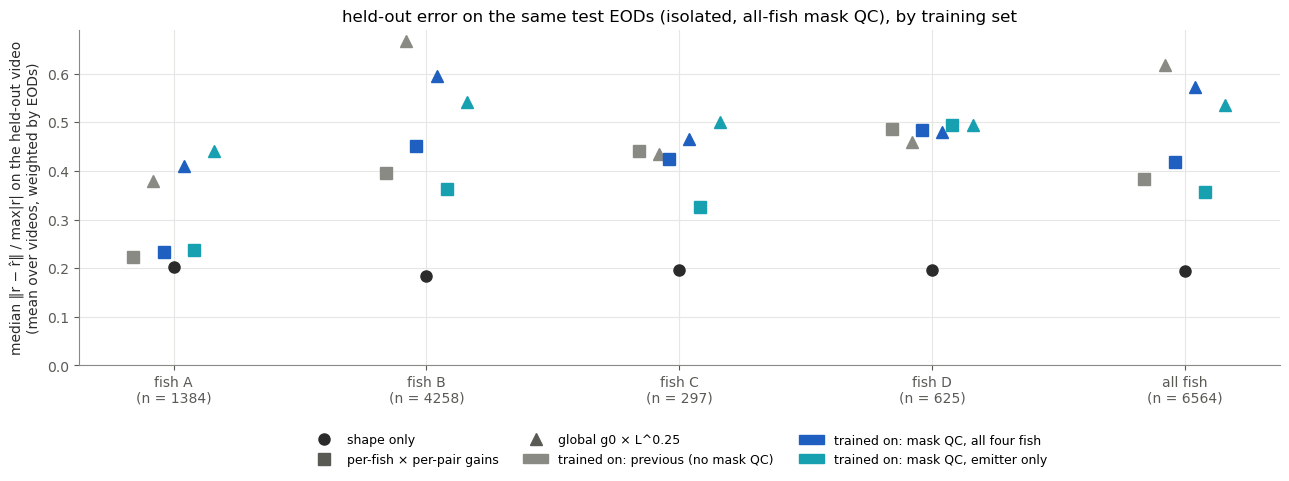

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
groups = list(LET) + ['all']; x = np.arange(len(groups))
ax.plot(x, summ.loc[('shape only', '—'), groups], color='#2b2b2b', marker='o', ms=8, lw=0, label='shape only')
for k, s in enumerate(SETS):
    for nm, mk in [('per-fish × per-pair', 's'), ('g0 L^0.25', '^')]:
        ax.plot(x + (k - 1) * 0.12 + (0.04 if mk == '^' else -0.04), summ.loc[(nm, s), groups], marker=mk, ms=8, lw=0, color=COL[s])
ntest = ERR[(ERR.fit == 'shape only')].groupby('fish').n.sum().reindex(groups)
ax.set(xticks=x, xticklabels=[f'{"fish " + g if g != "all" else "all fish"}\n(n = {ntest[g]})' for g in groups], ylim=(0, None),
       ylabel='median ‖r − r̂‖ / max|r| on the held-out video\n(mean over videos, weighted by EODs)',
       title='held-out error on the same test EODs (isolated, all-fish mask QC), by training set')
h = [Line2D([], [], marker='o', ls='', color='#2b2b2b', ms=8, label='shape only'),
     Line2D([], [], marker='s', ls='', color='#5a5a55', ms=8, label='per-fish × per-pair gains'),
     Line2D([], [], marker='^', ls='', color='#5a5a55', ms=8, label='global g0 × L^0.25')] + [Patch(color=COL[s], label=f'trained on: {s}') for s in SETS]
ax.legend(handles=h, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)
plt.tight_layout(); fig.savefig(f'{OUT}/held_out_error_previous_vs_mask_qc.png', dpi=120, bbox_inches='tight'); plt.show()